<a href="https://colab.research.google.com/github/shahmeerkhan12/FronEndDev/blob/main/deep_recommendation_sys.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Installing dependencies

In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
files.upload()

# Loading Dataset


In [ ]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d retailrocket/ecommerce-dataset
!unzip ecommerce-dataset.zip

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split


In [ ]:
!pip install tensorflow
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, Flatten, Concatenate, Dense
from tensorflow.keras.models import Model

Prepare Data for Model


In [ ]:
def prepare_ncf_data(events_data):
    # Create user and item mappings
    user_ids = events_data['visitorid'].unique()
    item_ids = events_data['itemid'].unique()

    user_to_index = {user: idx for idx, user in enumerate(user_ids)}
    item_to_index = {item: idx for idx, item in enumerate(item_ids)}

    # Map IDs to indices
    events_data['user_index'] = events_data['visitorid'].map(user_to_index)
    events_data['item_index'] = events_data['itemid'].map(item_to_index)

    # Split data (random splitting)
    # train, test = train_test_split(data, test_size=0.2, random_state=42)

    # we will go for a time-based spliting here
      # Time-based splitting (correct approach)
    cutoff_time = events_data['timestamp'].quantile(0.8)
    train = events_data[events_data['timestamp'] < cutoff_time]
    test = events_data[events_data['timestamp'] >= cutoff_time]
    # we will go for a time-based spliting here

  # include negative samples

      # 1. Get all possible user-item pairs from training period
    train_pos_pairs = set(zip(train['visitorid'], train['itemid']))

    # 2. Generate negative samples (avoid positive pairs)
    negative_samples = []
    all_train_items = train['itemid'].unique()

    for user in train['visitorid'].unique():
        # Get items user hasn't interacted with
        user_items = set(train[train['visitorid'] == user]['itemid'])
        negative_items = np.random.choice(
            [item for item in all_train_items if item not in user_items],
            size=min(len(user_items), 10),  # 1-10 negatives per positive
            replace=False
        )
        negative_samples.extend([(user, item, 0) for item in negative_items])

    # 3. Create DataFrame
    negative_df = pd.DataFrame(negative_samples,
                              columns=['visitorid', 'itemid', 'label'])

    # 4. Add metadata to negatives
    negative_df = negative_df.merge(
        events_data[['visitorid', 'user_index']].drop_duplicates(),
        on='visitorid'
    ).merge(
        events_data[['itemid', 'item_index']].drop_duplicates(),
        on='itemid'
    )

    # 5. Combine with positives
    train['label'] = 1  # Explicit positive labels
    train = pd.concat([train, negative_df], ignore_index=True)

    return train, test, len(user_ids), len(item_ids)

# Build the NCF model

In [ ]:
from tensorflow.keras import regularizers
from tensorflow.keras.metrics import AUC, PrecisionAtRecall, RecallAtPrecision
from tensorflow.keras.layers import Input, Embedding, Flatten, Concatenate, Dense, Dropout

def build_regularized_ncf(num_users, num_items):
    user_input = Input(shape=(1,))
    user_embed = Embedding(num_users, 32, embeddings_regularizer=regularizers.l2(1e-5))(user_input)

    item_input = Input(shape=(1,))
    item_embed = Embedding(num_items, 32, embeddings_regularizer=regularizers.l2(1e-5))(item_input)

    concat = Concatenate()([Flatten()(user_embed), Flatten()(item_embed)])

    # Add Dropout
    dense = Dense(64, activation='relu')(concat)
    dense = Dropout(0.5)(dense)

    output = Dense(1, activation='sigmoid')(dense)

    model = Model(inputs=[user_input, item_input], outputs=output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy',
                  metrics=[
                       'accuracy',
        AUC(name='auc'),                      # Area Under ROC Curve
        PrecisionAtRecall(0.8, name='par'),   # Precision at 80% recall
        RecallAtPrecision(0.8, name='rap')    # Recall at 80% precision
                  ])
    return model

# Data Exploration Visualization

In [ ]:
# data exploration visualization
import matplotlib.pyplot as plt
import seaborn as sns
!pip install wordcloud
from wordcloud import WordCloud
def load_and_preprocess_data():
    # Load datasets
    events = pd.read_csv('events.csv')
    item_properties1 = pd.read_csv('item_properties_part1.csv')
    item_properties2 = pd.read_csv('item_properties_part2.csv')
    category_tree = pd.read_csv('category_tree.csv')

    # Fix 1: Handle SettingWithCopyWarning properly
    positive_events = events[events['event'].isin(['addtocart', 'transaction'])].copy()
    positive_events.loc[:, 'label'] = 1  # Proper way to add column

    # Process item properties
    item_properties = pd.concat([item_properties1, item_properties2])
    item_properties = item_properties.sort_values('timestamp')

    item_features = (item_properties.groupby(['itemid', 'property'])['value']
                    .last()
                    .unstack()
                    .reset_index())

    # Fix 2: Ensure categoryid exists before processing
    if 'categoryid' in item_features.columns:
        item_features['categoryid'] = item_features['categoryid'].astype('category').cat.codes
    else:
        # If 'categoryid' is not in columns, add it with a default value (e.g., -1 or NaN)
        # Choosing NaN to represent missing data for categories
        item_features['categoryid'] = np.nan


    if 'available' in item_features.columns:
        item_features['available'] = item_features['available'].map({'true': 1, 'false': 0})
    else:
         # If 'available' is not in columns, add it with a default value (e.g., 0 or NaN)
        item_features['available'] = 0


    return positive_events, item_features

def plot_data_insights(data, item_features):
    plt.figure(figsize=(15, 12))

    # 1. Event Type Distribution
    plt.subplot(2, 2, 1)
    sns.countplot(x='event', data=data, order=data['event'].value_counts().index)
    plt.title('Distribution of Event Types')

    # 2. User Activity Timeline
    plt.subplot(2, 2, 2)
    data['date'] = pd.to_datetime(data['timestamp'], unit='ms')
    data.resample('D', on='date')['visitorid'].nunique().plot()
    plt.title('Daily Active Users')

    # 3. Item Popularity
    plt.subplot(2, 2, 3)
    data['itemid'].value_counts()[:20].plot(kind='barh')
    plt.title('Top 20 Most Popular Items')

    plt.tight_layout()
    plt.savefig('data_insights.png', dpi=300)
    plt.show()

# Visualizing the Model performance

In [ ]:
  # model performance visualization
def plot_model_performance(history, test_predictions, test_labels):
    plt.figure(figsize=(15, 5))

    # 1. Training History
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training History')
    plt.xlabel('Epochs')
    plt.ylabel('Binary Crossentropy')
    plt.legend()

    # 2. Prediction Distribution
    plt.subplot(1, 2, 2)
    sns.histplot(test_predictions, bins=50, kde=True)
    plt.title('Distribution of Predicted Scores')
    plt.xlabel('Prediction Score')

    plt.tight_layout()
    plt.savefig('model_performance.png', dpi=300)
    plt.show()

# Main Function

/tmp/ipython-input-31-1596716379.py:56: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train['label'] = 1  # Explicit positive labels


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_7       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 1, 32)     │  1,243,680 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_7         │ (None, 1, 32)     │    778,112 │ input_layer_7[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_16          │ (None, 32)        │          0 │ embedding_6[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_17          │ (None, 32)        │          0 │ embedding_7[0][0] │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_8       │ (None, 64)        │          0 │ flatten_16[0][0], │
│ (Concatenate)       │                   │            │ flatten_17[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 64)        │      4,160 │ concatenate_8[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,026,017 (7.73 MB)

 Trainable params: 2,026,017 (7.73 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
116/116 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.6148 - auc: 0.5273 - loss: 0.6810 - par: 0.6247 - rap: 0.0798 - val_accuracy: 1.0000 - val_auc: 0.0000e+00 - val_loss: 0.4922 - val_par: 1.0000 - val_rap: 1.0000
Epoch 2/10
116/116 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.6426 - auc: 0.7698 - loss: 0.5727 - par: 0.7441 - rap: 0.6998 - val_accuracy: 0.4355 - val_auc: 0.0000e+00 - val_loss: 0.5759 - val_par: 1.0000 - val_rap: 1.0000
Epoch 3/10
116/116 ━━━━━━━━━━━━━━━━━━━━ 7s 64ms/step - accuracy: 0.7466 - auc: 0.8168 - loss: 0.5104 - par: 0.7828 - rap: 0.7794 - val_accuracy: 0.4508 - val_auc: 0.0000e+00 - val_loss: 0.5685 - val_par: 1.0000 - val_rap: 1.0000
Epoch 4/10
116/116 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.7701 - auc: 0.8655 - loss: 0.4521 - par: 0.8137 - rap: 0.8298 - val_accuracy: 0.4209 - val_auc: 0.0000e+00 - val_loss: 0.5785 - val_par: 1.0000 - val_rap: 1.0000
Epoch 5/10
116/116 ━━━━━━━━━━━━━━━━━━━━ 8s 65ms/step - accuracy: 0.8032 - auc: 0.91

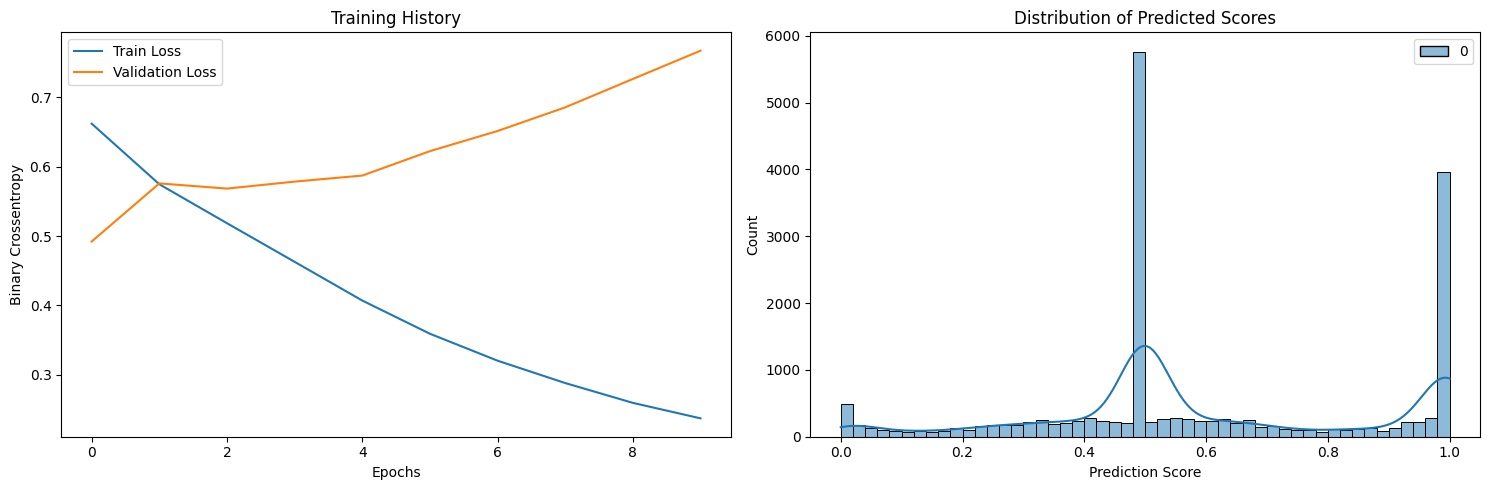

Available history keys: dict_keys(['accuracy', 'auc', 'loss', 'par', 'rap', 'val_accuracy', 'val_auc', 'val_loss', 'val_par', 'val_rap'])


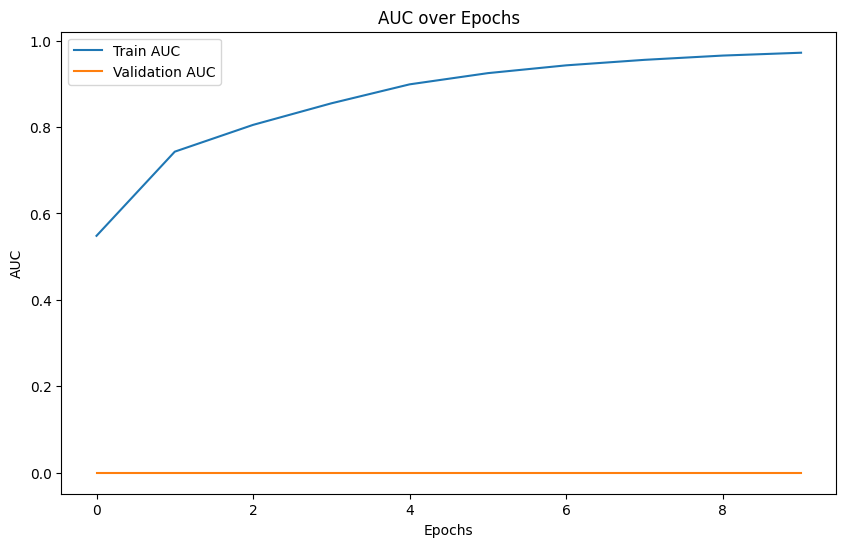

In [ ]:
# 4. Main execution
def main():
  # Load and preprocess data
    data, item_features = load_and_preprocess_data()
    # first visualization of raw data
    # plot_data_insights(data, item_features)

    # Prepare NCF data
    train, test, num_users, num_items = prepare_ncf_data(data)

    # Build and train model
    model = build_regularized_ncf(num_users, num_items)
    model.summary()
    # Check if test set is empty before training
    if test.empty:
        print("Test set is empty. Skipping model training and performance visualization.")
        return None, None # Return None for model and history if no training
    else:

        history = model.fit(
            [train['user_index'], train['item_index']],
            train['label'],
            validation_data=([test['user_index'], test['item_index']], test['label']),
            epochs=10,
            batch_size=1024
        )
        # --- SECOND VISUALIZATION: MODEL PERFORMANCE ---
        print("\nGenerating model performance visualizations...")
        test_predictions = model.predict([test['user_index'], test['item_index']])
        plot_model_performance(history, test_predictions, test['label'])
        # Plot AUC vs val_AUC or Accuracy vs val_Accuracy as fallback
        plt.figure(figsize=(10, 6))
        print("Available history keys:", history.history.keys())
        if 'auc' in history.history and 'val_auc' in history.history:
            plt.plot(history.history['auc'], label='Train AUC')
            plt.plot(history.history['val_auc'], label='Validation AUC')
            plt.title('AUC over Epochs')
            plt.ylabel('AUC')
        elif 'accuracy' in history.history and 'val_accuracy' in history.history:
            plt.plot(history.history['accuracy'], label='Train Accuracy')
            plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
            plt.title('Accuracy over Epochs')
            plt.ylabel('Accuracy')
        else:
            print("AUC and Accuracy metrics not found in history.")

        plt.xlabel('Epochs')
        plt.legend()
        plt.show()


        return model, history

# Run the pipeline
model, history = main()